# Week 10: K-Means Clustering

### Research Question

Can K-Means clustering identify meaningful groups of NBA games
based on sportsbook expectations and historical team performance?

### Objectives

1. Explore the importance of feature scaling in K-Means.
2. Use the elbow method to investigate the number of clusters.
3. Evaluate cluster quality using silhouette scores.
4. Examine Euclidean and Manhattan distance metrics.
5. Interpret the basketball characteristics of each cluster.
6. Investigate whether clusters exhibit different scoring
   outcomes and sportsbook prediction errors.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    adjusted_rand_score

)
        
from sklearn.decomposition import PCA

In [2]:
# Load cleaned NBA dataset
df = pd.read_csv(
    "../data/processed/merged_games_betting.csv",
    low_memory=False
)

In [3]:
# Prepare chronological ordering
df["game_date"] = pd.to_datetime(df["gameDate"])

df = df.sort_values("game_date").reset_index(drop=True)

print("Dataset shape:", df.shape)

print("\nDate range:")
print(df["game_date"].min(), "to", df["game_date"].max())

# Examine potential clustering variables
candidate_features = [
    "total",
    "spread",
    "actual_total"
]

print("\nSummary statistics:")
display(df[candidate_features].describe().round(2))

print("\nMissing values:")
display(df[candidate_features].isna().sum())

Dataset shape: (21965, 55)

Date range:
2007-10-30 00:00:00 to 2025-06-19 00:00:00

Summary statistics:


,total,spread,actual_total
count,21965.00,21962.00,21965.00
mean,211.04,6.14,211.41
std,15.20,3.68,23.28
min,170.00,0.00,134.00
25%,199.00,3.50,195.00
50%,211.50,5.50,211.00
75%,222.50,8.50,227.00
max,262.50,23.50,351.00



Missing values:


total           0
spread          3
actual_total    0
dtype: int64

## Historical Feature Engineering

K-Means clustering will use sportsbook information and recent
team-performance statistics to identify different types of NBA games.

Five clustering features are selected to represent expected scoring,
game competitiveness, recent scoring trends, and team rest.

Rolling averages use only previous games to prevent data leakage.
Actual game totals are excluded from clustering and reserved for
interpreting the resulting clusters.

In [4]:
# Create historical team-performance features
games = df.copy()

# Create one observation per team per game
home_games = pd.DataFrame({
    "team": games["hometeamId"].astype(str),
    "game_date": games["game_date"],
    "points_for": games["homeScore"],
    "points_against": games["awayScore"],
    "residual": games["actual_total"] - games["total"]
})

away_games = pd.DataFrame({
    "team": games["awayteamId"].astype(str),
    "game_date": games["game_date"],
    "points_for": games["awayScore"],
    "points_against": games["homeScore"],
    "residual": games["actual_total"] - games["total"]
})

team_games = pd.concat(
    [home_games, away_games],
    ignore_index=True
)

# Aggregate by date to avoid using another game from the same day
daily = (
    team_games
    .groupby(["team", "game_date"], as_index=False)
    .agg({
        "points_for": "mean",
        "points_against": "mean",
        "residual": "mean"
    })
    .sort_values(["team", "game_date"])
    .reset_index(drop=True)
)

# Five-game rolling averages based on past games only
for col in ["points_for", "points_against", "residual"]:
    daily[f"{col}_5"] = (
        daily.groupby("team")[col]
        .transform(
            lambda s: s.shift(1).rolling(
                window=5,
                min_periods=3
            ).mean()
        )
    )

# Days since the team's previous game, minus one
previous_date = daily.groupby("team")["game_date"].shift(1)

daily["rest_days"] = (
    (daily["game_date"] - previous_date).dt.days - 1
).clip(lower=0, upper=7)

history_cols = [
    "points_for_5",
    "points_against_5",
    "residual_5",
    "rest_days"
]

# Prepare home and away histories for merging
home_history = daily[
    ["team", "game_date"] + history_cols
].rename(columns={
    "team": "hometeamId",
    **{c: f"home_{c}" for c in history_cols}
})

away_history = daily[
    ["team", "game_date"] + history_cols
].rename(columns={
    "team": "awayteamId",
    **{c: f"away_{c}" for c in history_cols}
})

# Match team ID types
games["hometeamId"] = games["hometeamId"].astype(str)
games["awayteamId"] = games["awayteamId"].astype(str)

# Merge historical features
games = games.merge(
    home_history,
    on=["hometeamId", "game_date"],
    how="left",
    validate="many_to_one"
)

games = games.merge(
    away_history,
    on=["awayteamId", "game_date"],
    how="left",
    validate="many_to_one"
)

# Estimate game totals using historical offense and defense
games["expected_total_5"] = (
    games["home_points_for_5"]
    + games["away_points_against_5"]
    + games["away_points_for_5"]
    + games["home_points_against_5"]
) / 2

# Compare the historical estimate with the sportsbook total
games["scoring_edge_5"] = (
    games["expected_total_5"] - games["total"]
)

# Recent results compared with sportsbook expectations
games["recent_residual_5"] = (
    games["home_residual_5"]
    + games["away_residual_5"]
) / 2

# Difference between home and away rest
games["rest_difference"] = (
    games["home_rest_days"]
    - games["away_rest_days"]
)

# Final clustering features
cluster_features = [
    "total",
    "spread",
    "scoring_edge_5",
    "recent_residual_5",
    "rest_difference"
]

print("Dataset shape:", games.shape)

print("\nClustering feature summary:")
display(games[cluster_features].describe().round(2))

print("\nMissing values:")
display(games[cluster_features].isna().sum())

Dataset shape: (21965, 67)

Clustering feature summary:


,total,spread,scoring_edge_5,recent_residual_5,rest_difference
count,21965.00,21962.00,21911.00,21911.00,21945.00
mean,211.04,6.14,0.31,0.36,0.19
std,15.20,3.68,6.64,5.85,1.19
min,170.00,0.00,-31.60,-29.20,-7.00
25%,199.00,3.50,-4.10,-3.55,0.00
50%,211.50,5.50,0.40,0.35,0.00
75%,222.50,8.50,4.70,4.30,1.00
max,262.50,23.50,32.90,26.80,7.00



Missing values:


total                 0
spread                3
scoring_edge_5       54
recent_residual_5    54
rest_difference      20
dtype: int64

## Data Preparation and Feature Scaling

The dataset is divided chronologically into training and testing
periods to evaluate whether historical NBA game clusters remain
meaningful in more recent seasons.

Missing values are replaced using training-data medians.

StandardScaler is applied because K-Means relies on Euclidean
distances, and features with larger numerical scales can
dominate the clustering process.

Imputation and scaling parameters are calculated using only
the training dataset to prevent data leakage.

In [5]:
# Chronological split and feature scaling

# Chronological 80/20 split
split_idx = int(len(games) * 0.80)
cutoff_date = games.iloc[split_idx]["game_date"]

train_df = games[
    games["game_date"] < cutoff_date
].copy()

test_df = games[
    games["game_date"] >= cutoff_date
].copy()

# Select clustering features
X_train = train_df[cluster_features]
X_test = test_df[cluster_features]

# Impute missing values
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Check the split
print("Training games:", len(train_df))
print("Testing games:", len(test_df))

print("\nTraining period:")
print(train_df["game_date"].min(), "to",
      train_df["game_date"].max())

print("\nTesting period:")
print(test_df["game_date"].min(), "to",
      test_df["game_date"].max())

# Compare original and standardized feature distributions
scaling_comparison = pd.DataFrame({
    "Feature": cluster_features,
    "Original Mean": X_train_imputed.mean(axis=0),
    "Original Std": X_train_imputed.std(axis=0),
    "Scaled Mean": X_train_scaled.mean(axis=0),
    "Scaled Std": X_train_scaled.std(axis=0)
})

print("\nFeature scaling comparison:")
display(scaling_comparison.round(4))

# Examine potential redundant features
print("\nFeature correlation matrix:")
display(
    pd.DataFrame(
        X_train_scaled,
        columns=cluster_features
    ).corr().round(3)
)

Training games: 17568
Testing games: 4397

Training period:
2007-10-30 00:00:00 to 2022-02-16 00:00:00

Testing period:
2022-02-17 00:00:00 to 2025-06-19 00:00:00

Feature scaling comparison:


,Feature,Original Mean,Original Std,Scaled Mean,Scaled Std
0,total,207.0941,13.7647,0.0,1.0
1,spread,6.0880,3.6128,0.0,1.0
2,scoring_edge_5,0.2359,6.6425,0.0,1.0
3,recent_residual_5,0.3064,5.8619,-0.0,1.0
4,rest_difference,0.2107,1.2323,0.0,1.0



Feature correlation matrix:


,total,spread,scoring_edge_5,recent_residual_5,rest_difference
total,1.000,0.046,-0.368,0.159,-0.025
spread,0.046,1.000,-0.070,-0.009,0.058
scoring_edge_5,-0.368,-0.070,1.000,0.587,-0.014
recent_residual_5,0.159,-0.009,0.587,1.000,-0.002
rest_difference,-0.025,0.058,-0.014,-0.002,1.000


## K-Means Clustering: Elbow Method

The elbow method is used to investigate the appropriate number
of clusters for NBA games.

K-Means models are fitted using different numbers of clusters
(k = 2 through 10).

For each model, within-cluster sum of squared errors (inertia)
is calculated.

A sharp decrease in inertia followed by a slower decline
may indicate a reasonable number of clusters.

,Number of Clusters,Inertia
0,2,69745.33
1,3,60687.56
2,4,53725.46
3,5,48908.50
4,6,44753.22
5,7,42126.07
6,8,39807.04
7,9,37856.39
8,10,36168.84


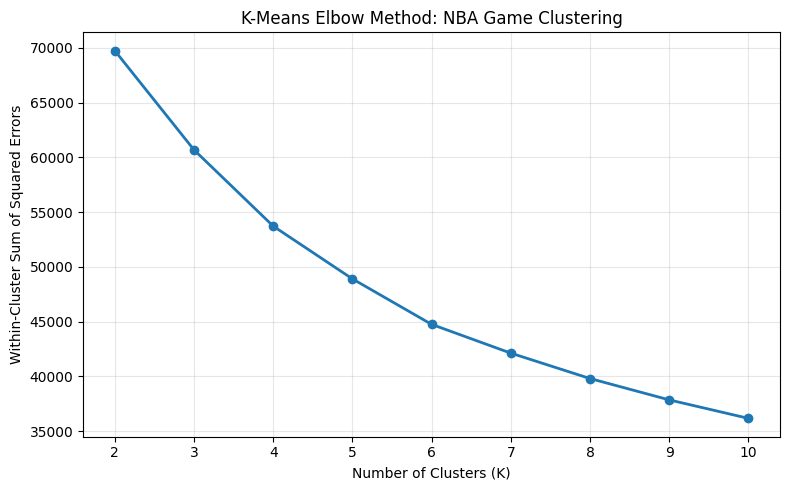

In [7]:
# Evaluate different numbers of clusters
k_values = range(2, 11)

inertia_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    kmeans.fit(X_train_scaled)

    inertia_values.append(kmeans.inertia_)

# Store results
elbow_results = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Inertia": inertia_values
})

display(elbow_results.round(2))

# Plot elbow curve
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squared Errors")
plt.title("K-Means Elbow Method: NBA Game Clustering")

plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## Silhouette Score Analysis

The elbow method suggested that four clusters may be a reasonable
choice for NBA game clustering.

Silhouette scores are calculated for K=2 through K=10 to evaluate
cluster separation and cohesion.

Euclidean and Manhattan distances are compared when evaluating
the same K-Means cluster assignments.

A reproducible sample of 2,000 training games is used to
reduce computational costs.

,K,Euclidean Silhouette,Manhattan Silhouette
0,2,0.1996,0.2191
1,3,0.1683,0.1854
2,4,0.1662,0.1690
3,5,0.1773,0.1747
4,6,0.1748,0.1712
5,7,0.1737,0.1665
6,8,0.1770,0.1708
7,9,0.1677,0.1624
8,10,0.1569,0.1514


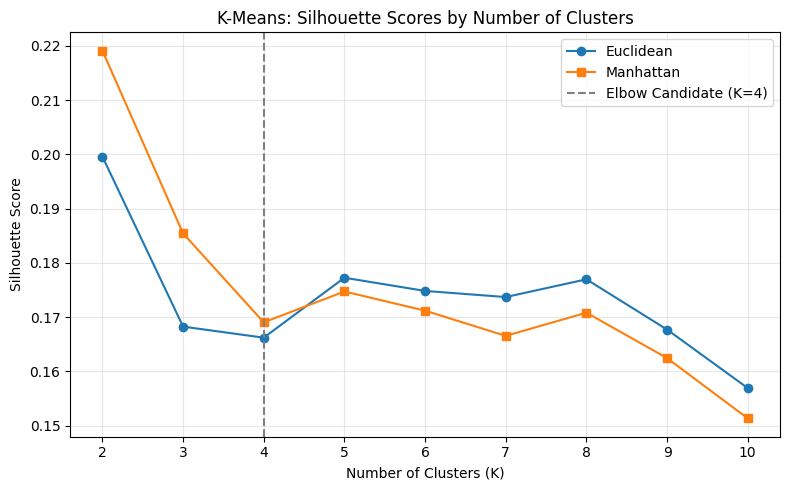

In [8]:
# Silhouette Score Analysis

k_values = range(2, 11)

silhouette_results = []

for k in k_values:

    # Fit K-Means using standardized training features
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_train_scaled)

    # Evaluate separation using different distance metrics
    euclidean_score = silhouette_score(
        X_train_scaled,
        labels,
        metric="euclidean",
        sample_size=2000,
        random_state=42
    )

    manhattan_score = silhouette_score(
        X_train_scaled,
        labels,
        metric="manhattan",
        sample_size=2000,
        random_state=42
    )

    silhouette_results.append({
        "K": k,
        "Euclidean Silhouette": euclidean_score,
        "Manhattan Silhouette": manhattan_score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df.round(4))

# Visualize the results
plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_df["K"],
    silhouette_df["Euclidean Silhouette"],
    marker="o",
    label="Euclidean"
)

plt.plot(
    silhouette_df["K"],
    silhouette_df["Manhattan Silhouette"],
    marker="s",
    label="Manhattan"
)

# Highlight candidate K=4
plt.axvline(
    x=4,
    linestyle="--",
    color="gray",
    label="Elbow Candidate (K=4)"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means: Silhouette Scores by Number of Clusters")

plt.xticks(list(k_values))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Comparing Cluster Profiles: K=2 vs K=4

The elbow method suggested 4 clusters, while silhouette
analysis favored 2 clusters.

Both solutions are evaluated to determine whether they
identify meaningful groups of NBA games.

Cluster profiles are examined using sportsbook totals,
point spreads, recent scoring trends, and rest differences.

Actual game scores and sportsbook errors are analyzed
after clustering to evaluate whether the groups differ
in their outcomes.

In [9]:
# Compare K=2 and K=4 cluster profiles

cluster_models = {}

for k in [2, 4]:

    # Fit K-Means on historical training games only
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    model.fit(X_train_scaled)
    cluster_models[k] = model

    # Assign clusters to historical and recent games
    train_labeled = train_df.copy()
    test_labeled = test_df.copy()

    train_labeled["Cluster"] = model.predict(X_train_scaled)
    test_labeled["Cluster"] = model.predict(X_test_scaled)

    # Actual outcomes are used for interpretation only
    test_labeled["Sportsbook Error"] = (
        test_labeled["actual_total"] - test_labeled["total"]
    ).abs()

    # Profile recent NBA games by cluster
    test_profile = (
        test_labeled
        .groupby("Cluster")
        .agg(
            Games=("actual_total", "size"),
            Avg_Sportsbook_Total=("total", "mean"),
            Avg_Spread=("spread", "mean"),
            Avg_Scoring_Edge=("scoring_edge_5", "mean"),
            Avg_Recent_Residual=("recent_residual_5", "mean"),
            Avg_Rest_Difference=("rest_difference", "mean"),
            Avg_Actual_Total=("actual_total", "mean"),
            Sportsbook_MAE=("Sportsbook Error", "mean")
        )
    )

    # Calculate percentages of games in each cluster
    test_profile["Share (%)"] = (
        test_profile["Games"] / len(test_labeled) * 100
    )

    print(f"\n{'='*40}")
    print(f"K = {k}: Recent NBA Game Profiles")
    print(f"{'='*40}")

    display(test_profile.round(2))


K = 2: Recent NBA Game Profiles


,Games,Avg_Sportsbook_Total,Avg_Spread,Avg_Scoring_Edge,Avg_Recent_Residual,Avg_Rest_Difference,Avg_Actual_Total,Sportsbook_MAE,Share (%)
Cluster,,,,,,,,,
0,1676,223.60,5.98,6.88,5.14,0.1,224.15,14.32,38.12
1,2721,228.82,6.60,-3.23,-2.20,0.1,229.44,14.02,61.88



K = 4: Recent NBA Game Profiles


,Games,Avg_Sportsbook_Total,Avg_Spread,Avg_Scoring_Edge,Avg_Recent_Residual,Avg_Rest_Difference,Avg_Actual_Total,Sportsbook_MAE,Share (%)
Cluster,,,,,,,,,
0,1527,225.27,5.19,6.47,5.68,0.05,225.42,14.26,34.73
1,933,226.58,11.94,0.25,-0.03,0.40,228.14,14.50,21.22
2,90,207.76,4.11,5.04,-4.58,0.11,207.97,13.51,2.05
3,1847,229.18,4.63,-4.23,-3.04,-0.01,229.66,13.89,42.01


## Cluster Stability and Scoring Outcomes

The K=2 and K=4 clustering solutions are compared across
historical training games and more recent testing games.

The analysis examines:
- Cluster sizes and proportions
- Average signed sportsbook prediction errors
- Sportsbook mean absolute errors
- Percentage of games finishing Over the sportsbook total

These comparisons help determine whether the clusters
describe stable and meaningful NBA game profiles.

In [10]:
# Compare cluster outcomes across time periods

cluster_stability_results = []

for k in [2, 4]:

    model = cluster_models[k]

    for period, source_df, X_scaled in [
        ("Training", train_df, X_train_scaled),
        ("Testing", test_df, X_test_scaled)
    ]:

        temp = source_df.copy()

        # Assign games using the training-fitted K-Means model
        temp["Cluster"] = model.predict(X_scaled)

        # Signed sportsbook error
        temp["Signed_Error"] = (
            temp["actual_total"] - temp["total"]
        )

        temp["Absolute_Error"] = temp["Signed_Error"].abs()

        # Exclude pushes when calculating Over percentages
        temp["Over"] = np.where(
            temp["Signed_Error"] == 0,
            np.nan,
            (temp["Signed_Error"] > 0).astype(float)
        )

        summary = temp.groupby("Cluster").agg(
            Games=("actual_total", "size"),
            Avg_Signed_Error=("Signed_Error", "mean"),
            Sportsbook_MAE=("Absolute_Error", "mean"),
            Over_Rate=("Over", "mean")
        )

        summary["Share_Pct"] = (
            summary["Games"] / len(temp) * 100
        )

        summary["Over_Rate"] *= 100

        summary = summary.reset_index()
        summary["K"] = k
        summary["Period"] = period

        cluster_stability_results.append(summary)

cluster_stability_df = pd.concat(
    cluster_stability_results,
    ignore_index=True
)

display(
    cluster_stability_df[
        [
            "K",
            "Period",
            "Cluster",
            "Games",
            "Share_Pct",
            "Avg_Signed_Error",
            "Sportsbook_MAE",
            "Over_Rate"
        ]
    ].round(2)
)

,K,Period,Cluster,Games,Share_Pct,Avg_Signed_Error,Sportsbook_MAE,Over_Rate
0,2,Training,0,8938,50.88,0.60,13.86,50.19
1,2,Training,1,8630,49.12,0.01,14.05,49.36
2,2,Testing,0,1676,38.12,0.55,14.32,50.69
3,2,Testing,1,2721,61.88,0.62,14.02,50.88
4,4,Training,0,4499,25.61,0.29,13.90,49.74
5,4,Training,1,3528,20.08,0.41,13.95,50.23
6,4,Training,2,4937,28.10,0.74,13.56,50.09
7,4,Training,3,4604,26.21,-0.21,14.43,49.15
8,4,Testing,0,1527,34.73,0.15,14.26,49.51
9,4,Testing,1,933,21.22,1.56,14.50,53.56


## Impact of Feature Scaling on K-Means

This experiment investigates how standardizing NBA features
changes K-Means clustering.

Two models are compared:
- K-Means using original feature values.
- K-Means using standardized features.

Silhouette scores are calculated using a reproducible sample
of training games.

The goal is to evaluate whether feature scaling improves
cluster separation and changes cluster assignments.

In [13]:
# K-Means without scaling
kmeans_unscaled = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)

unscaled_labels = kmeans_unscaled.fit_predict(
    X_train_imputed
)

# Use our existing scaled K-Means model
kmeans_scaled = cluster_models[2]
scaled_labels = kmeans_scaled.labels_

# Evaluate the same 2,000 observations
rng = np.random.default_rng(42)

sample_idx = rng.choice(
    len(X_train_scaled),
    size=2000,
    replace=False
)

unscaled_silhouette = silhouette_score(
    X_train_imputed[sample_idx],
    unscaled_labels[sample_idx]
)

scaled_silhouette = silhouette_score(
    X_train_scaled[sample_idx],
    scaled_labels[sample_idx]
)

# Compare cluster assignments
ari = adjusted_rand_score(
    unscaled_labels,
    scaled_labels
)

scaling_results = pd.DataFrame({
    "Model": ["Without Scaling", "With StandardScaler"],
    "Silhouette Score": [
        unscaled_silhouette,
        scaled_silhouette
    ],
    "Inertia": [
        kmeans_unscaled.inertia_,
        kmeans_scaled.inertia_
    ]
})

display(scaling_results.round(4))

print(
    "Adjusted Rand Index between assignments:",
    round(ari, 4)
)

# Show how the models' clusters differ in original units
raw_centers = pd.DataFrame(
    kmeans_unscaled.cluster_centers_,
    columns=cluster_features
)

scaled_centers = pd.DataFrame(
    scaler.inverse_transform(kmeans_scaled.cluster_centers_),
    columns=cluster_features
)

print("\nUnscaled cluster centers:")
display(raw_centers.round(2))

print("\nScaled cluster centers (original units):")
display(scaled_centers.round(2))

,Model,Silhouette Score,Inertia
0,Without Scaling,0.3850,2.606210e+06
1,With StandardScaler,0.1886,6.974533e+04


Adjusted Rand Index between assignments: 0.0975

Unscaled cluster centers:


,total,spread,scoring_edge_5,recent_residual_5,rest_difference
0,195.86,5.91,2.44,-0.18,0.23
1,218.57,6.27,-2.02,0.80,0.19



Scaled cluster centers (original units):


,total,spread,scoring_edge_5,recent_residual_5,rest_difference
0,202.74,5.66,5.10,3.76,0.18
1,211.59,6.53,-4.79,-3.26,0.24



## Conclusions and Key Findings

### K-Means and Cluster Selection

K-Means clustering was applied to NBA games using sportsbook totals, point spreads, historical scoring trends, and rest-day differences.

The elbow method suggested K=4 as a reasonable candidate, while silhouette analysis favored K=2. The highest Euclidean silhouette score was 0.1996, indicating that the clusters were not strongly separated.

K=2 was selected as the primary solution because it provided better separation and interpretable groups.

### Cluster Interpretation

The K=2 model identified two broad types of NBA matchups:

- Cluster 0: Games with positive historical scoring trends relative to sportsbook expectations.
- Cluster 1: Games with negative historical scoring trends relative to sportsbook expectations.

However, testing-period Over rates were approximately 50.69% and 50.88%, respectively.

These results suggest that the clusters describe different pregame characteristics but do not provide a clear advantage in predicting Over/Under outcomes.

### Cluster Stability

Cluster membership changed between historical and recent NBA games. Under K=2, Cluster 0 represented 50.88% of training games but only 38.12% of testing games.

The K=4 solution exhibited an even larger shift, with one cluster declining from 28.10% of training games to 2.05% of testing games.

These findings suggest that the historical NBA scoring environment has changed, limiting the stability of some clustering patterns.

### Feature Scaling and Distance Metrics

Feature scaling substantially influenced K-Means results.

Without scaling, the silhouette score was 0.3850, compared with 0.1886 after standardization on a separate reproducible sample.

These scores are not directly comparable because the distance scales differ. However, the cluster profiles revealed that unscaled K-Means primarily separated games by sportsbook totals, while standardized K-Means placed greater emphasis on multiple basketball characteristics.

The Adjusted Rand Index between the two clustering solutions was 0.0975, indicating limited agreement.

Manhattan and Euclidean silhouette evaluations also showed differences, although standard K-Means clustering was fitted using squared Euclidean distances.

### Overall Conclusion

K-Means successfully identified different NBA game profiles, but the resulting groups did not demonstrate a clear relationship with Over/Under prediction accuracy.
